# 레드와인 품질 데이터 분석 (Red Wine Quality)

**데이터셋**: UCI Machine Learning Repository - Wine Quality Data Set (Cortez et al., 2009)
**출처**: Kaggle `uciml/red-wine-quality-cortez-et-al-2009`
**목적**: 레드와인의 물리·화학적 측정값으로 품질(quality)을 설명하고, 우수 와인을 예측하는 모델을 만든다.

## 분석 목차
1. 데이터 로드 (kagglehub)
2. 데이터 개요 및 품질 확인
3. 기술 통계
4. 탐색적 데이터 분석(EDA)
5. 품질 예측 모델링
6. 결론

## 1. 데이터 로드

`kagglehub`로 데이터셋을 자동 다운로드하고 CSV를 불러온다.

In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# kagglehub로 최신 버전 데이터셋 다운로드
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("데이터 경로:", path)
print("CSV 파일:", os.path.basename(csv_path))

df = pd.read_csv(csv_path, sep=None, engine="python")
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df.head()

데이터 경로: C:\Users\user\.cache\kagglehub\datasets\uciml\red-wine-quality-cortez-et-al-2009\versions\2
CSV 파일: winequality-red.csv


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. 데이터 개요

행/열 크기, 컬럼 타입, 결측치, 중복값을 확인한다.

In [2]:
print("데이터 크기 (행, 열):", df.shape)
print("\n컬럼 목록:")
print(list(df.columns))
print("\n변수 설명:")
columns_desc = {
    "fixed_acidity": "고정 산도",
    "volatile_acidity": "휘발성 산도",
    "citric_acid": "구연산",
    "residual_sugar": "잔당",
    "chlorides": "염화물",
    "free_sulfur_dioxide": "유리 이산화황",
    "total_sulfur_dioxide": "총 이산화황",
    "density": "밀도",
    "pH": "pH",
    "sulphates": "황산염",
    "alcohol": "알코올 도수(%)",
    "quality": "품질 점수 (0~10, 목표 변수)",
}
for c, d in columns_desc.items():
    print(f"  - {c:22s} : {d}")

데이터 크기 (행, 열): (1599, 12)

컬럼 목록:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

변수 설명:
  - fixed_acidity          : 고정 산도
  - volatile_acidity       : 휘발성 산도
  - citric_acid            : 구연산
  - residual_sugar         : 잔당
  - chlorides              : 염화물
  - free_sulfur_dioxide    : 유리 이산화황
  - total_sulfur_dioxide   : 총 이산화황
  - density                : 밀도
  - pH                     : pH
  - sulphates              : 황산염
  - alcohol                : 알코올 도수(%)
  - quality                : 품질 점수 (0~10, 목표 변수)


In [3]:
print("데이터 타입:")
print(df.dtypes)
print("\n결측치 개수:", int(df.isna().sum().sum()))
print("중복 행 개수:", int(df.duplicated().sum()))
print("\n품질(quality) 점수 분포:")
print(df["quality"].value_counts().sort_index())

데이터 타입:
fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

결측치 개수: 0
중복 행 개수: 240

품질(quality) 점수 분포:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## 3. 기술 통계

각 변수의 평균·표준편차·사분위수와 왜도(skewness)를 확인한다.

In [4]:
desc = df.describe().T
desc["median"] = df.median()
desc["skew"] = df.skew()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,median,skew
fixed_acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900,7.900,0.983
volatile_acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580,0.520,0.672
citric_acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000,0.260,0.318
residual_sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500,2.200,4.541
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611,0.079,5.680
free_sulfur_dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000,14.000,1.251
total_sulfur_dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000,38.000,1.516
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.997,0.071
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010,3.310,0.194
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000,0.620,2.429


**관찰**
- `residual_sugar`, `chlorides`, `sulphates` 등은 오른쪽으로 긴 꼬리(양의 왜도)를 가진다.
- `alcohol`은 품질과 상대적으로 강한 관계를 보인다(아래 상관분석 참조).
- 결측치는 없으나 중복 행이 240개 존재한다(수집 과정의 동일 조건 측정으로 추정).

## 4. 탐색적 데이터 분석

### 4-1. 품질 점수 분포

목표 변수(quality)는 3~8 정수이며 5와 6에 크게 치우쳐 있다(불균형).

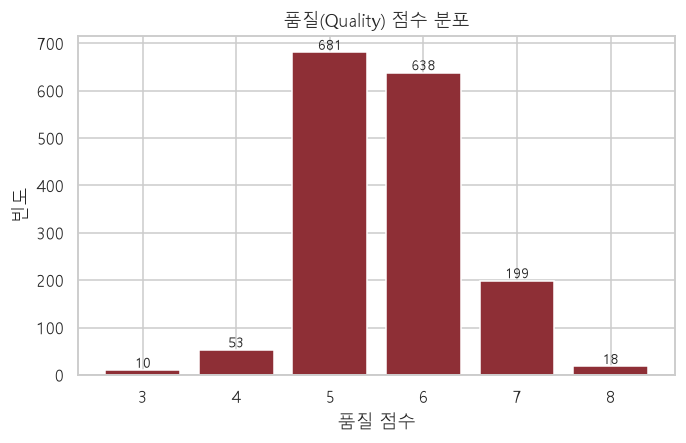

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df["quality"].value_counts().sort_index()
bars = ax.bar(counts.index.astype(str), counts.values, color="#8e2f36")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 5, str(v), ha="center", fontsize=9)
ax.set_title("품질(Quality) 점수 분포")
ax.set_xlabel("품질 점수")
ax.set_ylabel("빈도")
plt.show()

### 4-2. 변수별 분포

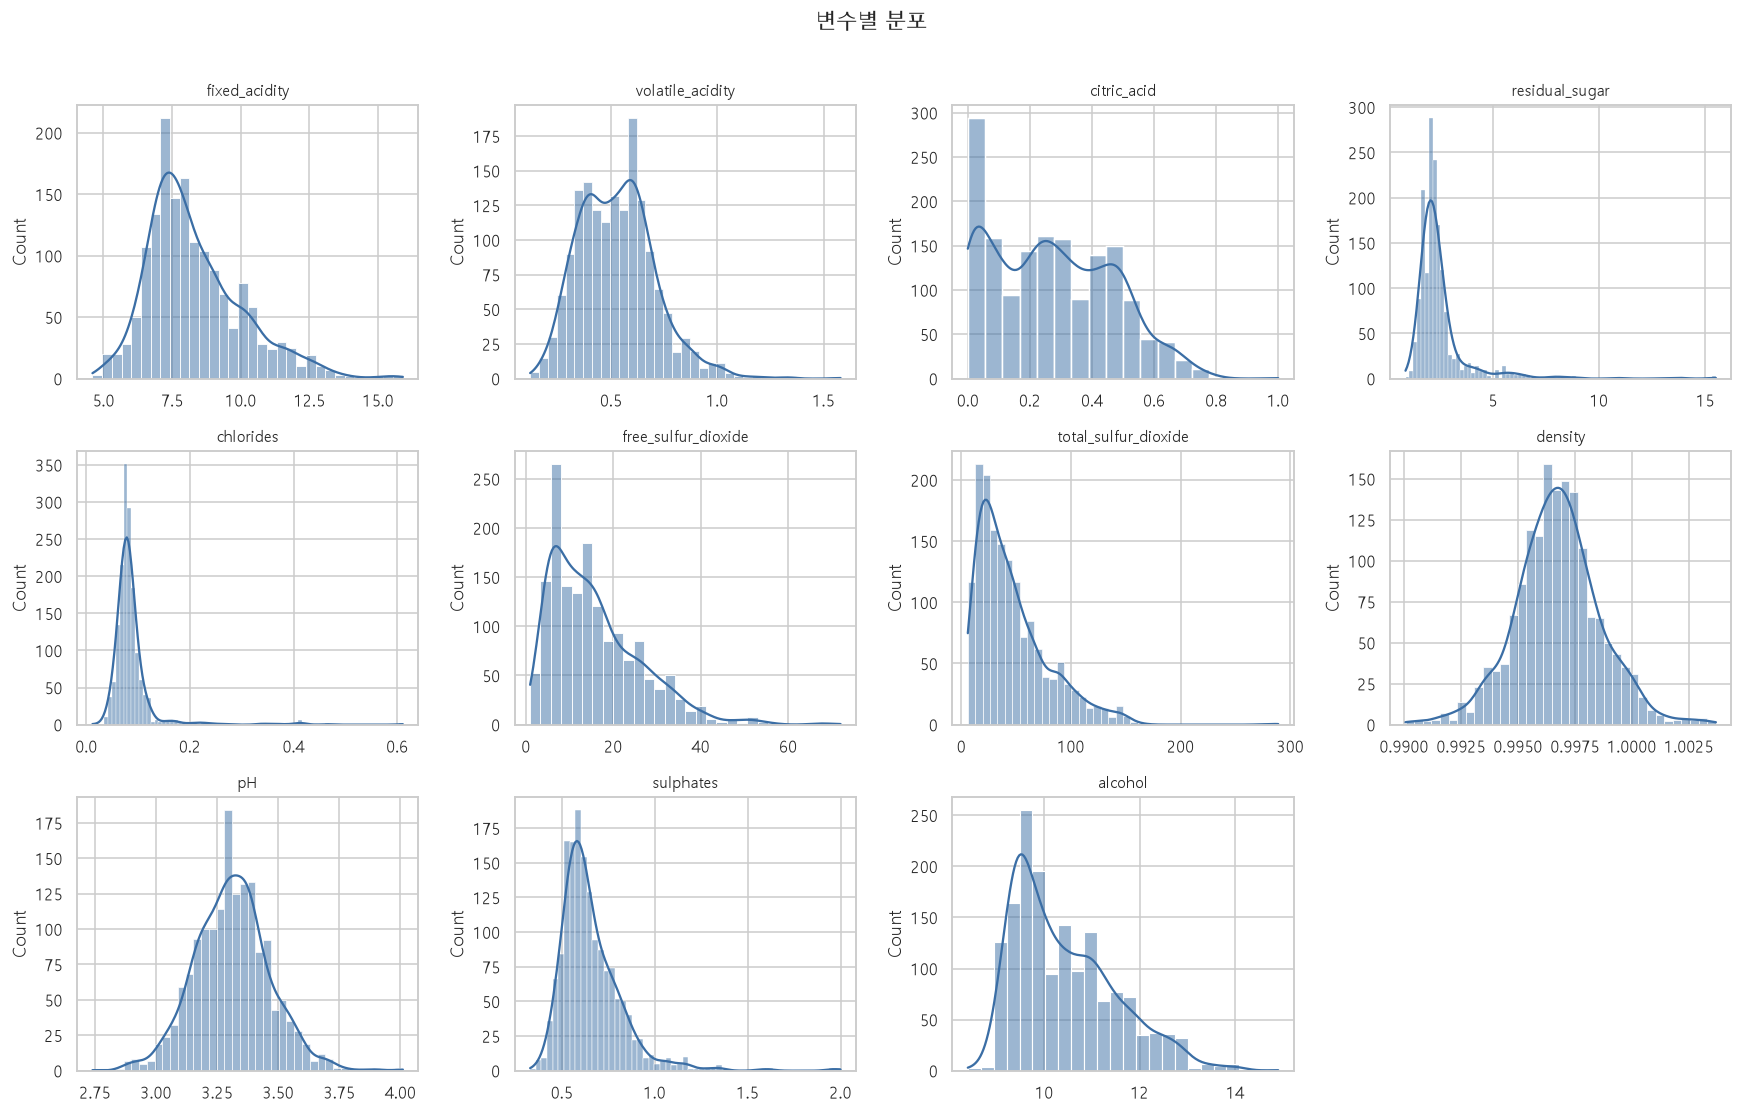

In [6]:
feats = [c for c in df.columns if c != "quality"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, f in zip(axes.ravel(), feats):
    sns.histplot(df[f], kde=True, ax=ax, color="#3b6ea5")
    ax.set_title(f, fontsize=10)
    ax.set_xlabel("")
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
fig.suptitle("변수별 분포", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 4-3. 상관관계 분석

품질과의 상관계수와 변수 간 상관 히트맵을 살펴본다.

In [7]:
corr_with_quality = df.corr(numeric_only=True)["quality"].drop("quality").sort_values(ascending=False)
print("품질과의 상관계수 (내림차순):")
print(corr_with_quality.round(3))

품질과의 상관계수 (내림차순):
alcohol                 0.476
sulphates               0.251
citric_acid             0.226
fixed_acidity           0.124
residual_sugar          0.014
free_sulfur_dioxide    -0.051
pH                     -0.058
chlorides              -0.129
density                -0.175
total_sulfur_dioxide   -0.185
volatile_acidity       -0.391
Name: quality, dtype: float64


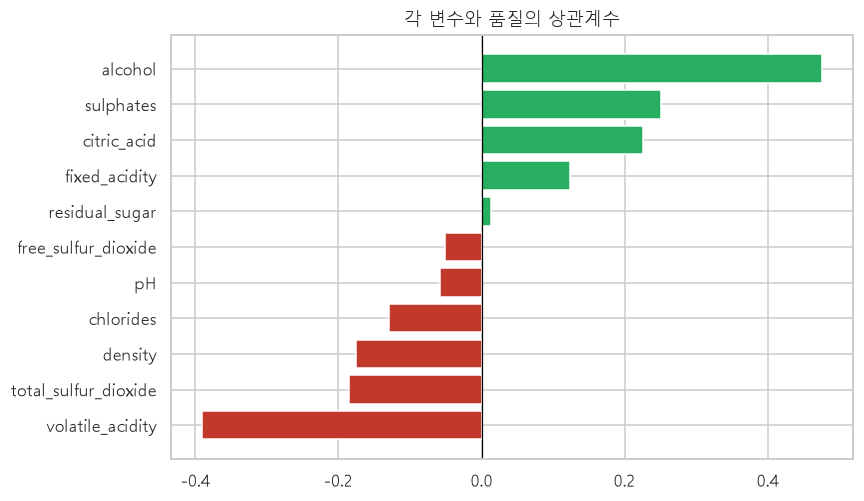

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c0392b" if v < 0 else "#27ae60" for v in corr_with_quality.values]
ax.barh(corr_with_quality.index[::-1], corr_with_quality.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("각 변수와 품질의 상관계수")
plt.show()

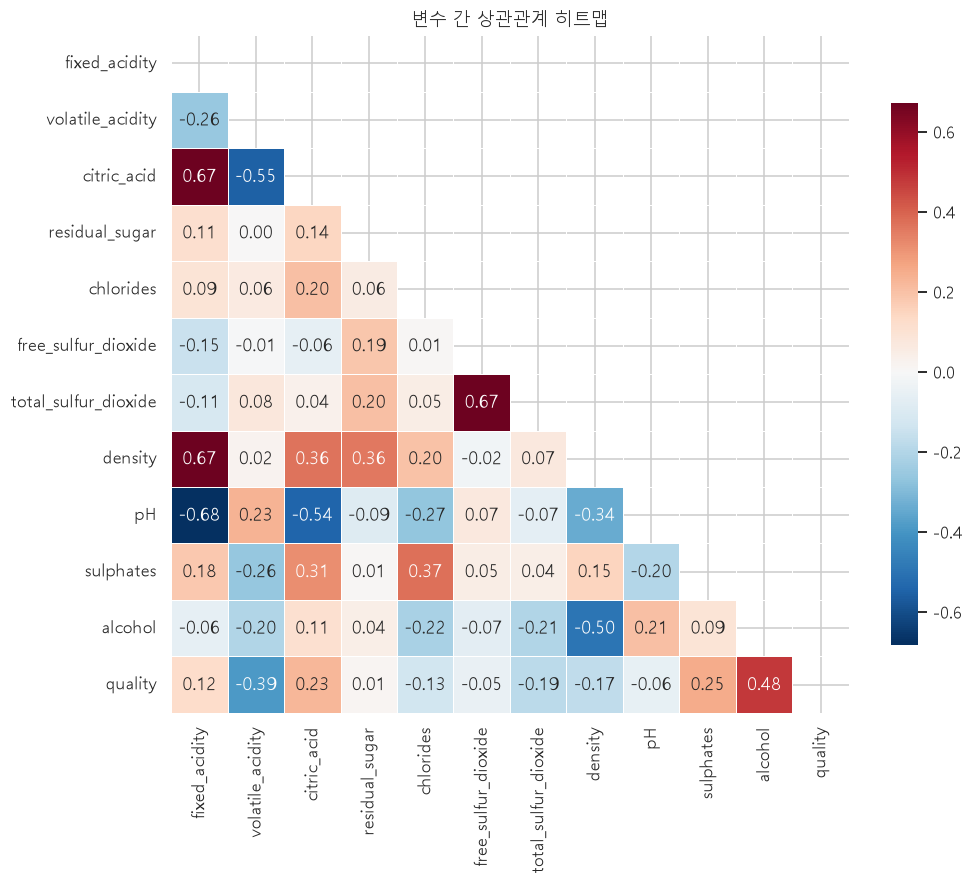

In [9]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("변수 간 상관관계 히트맵")
plt.show()

**핵심 상관관계**
- **알코올(+0.48)**, **황산염(+0.25)**, **구연산(+0.23)** 은 품질과 양의 상관.
- **휘발성 산도(-0.39)**, **총 이산화황(-0.19)**, **밀도(-0.18)** 는 품질과 음의 상관.
- `free_sulfur_dioxide`와 `total_sulfur_dioxide`는 서로 강한 상관(다중공선성)을 보인다.

### 4-4. 품질별 주요 변수 분포

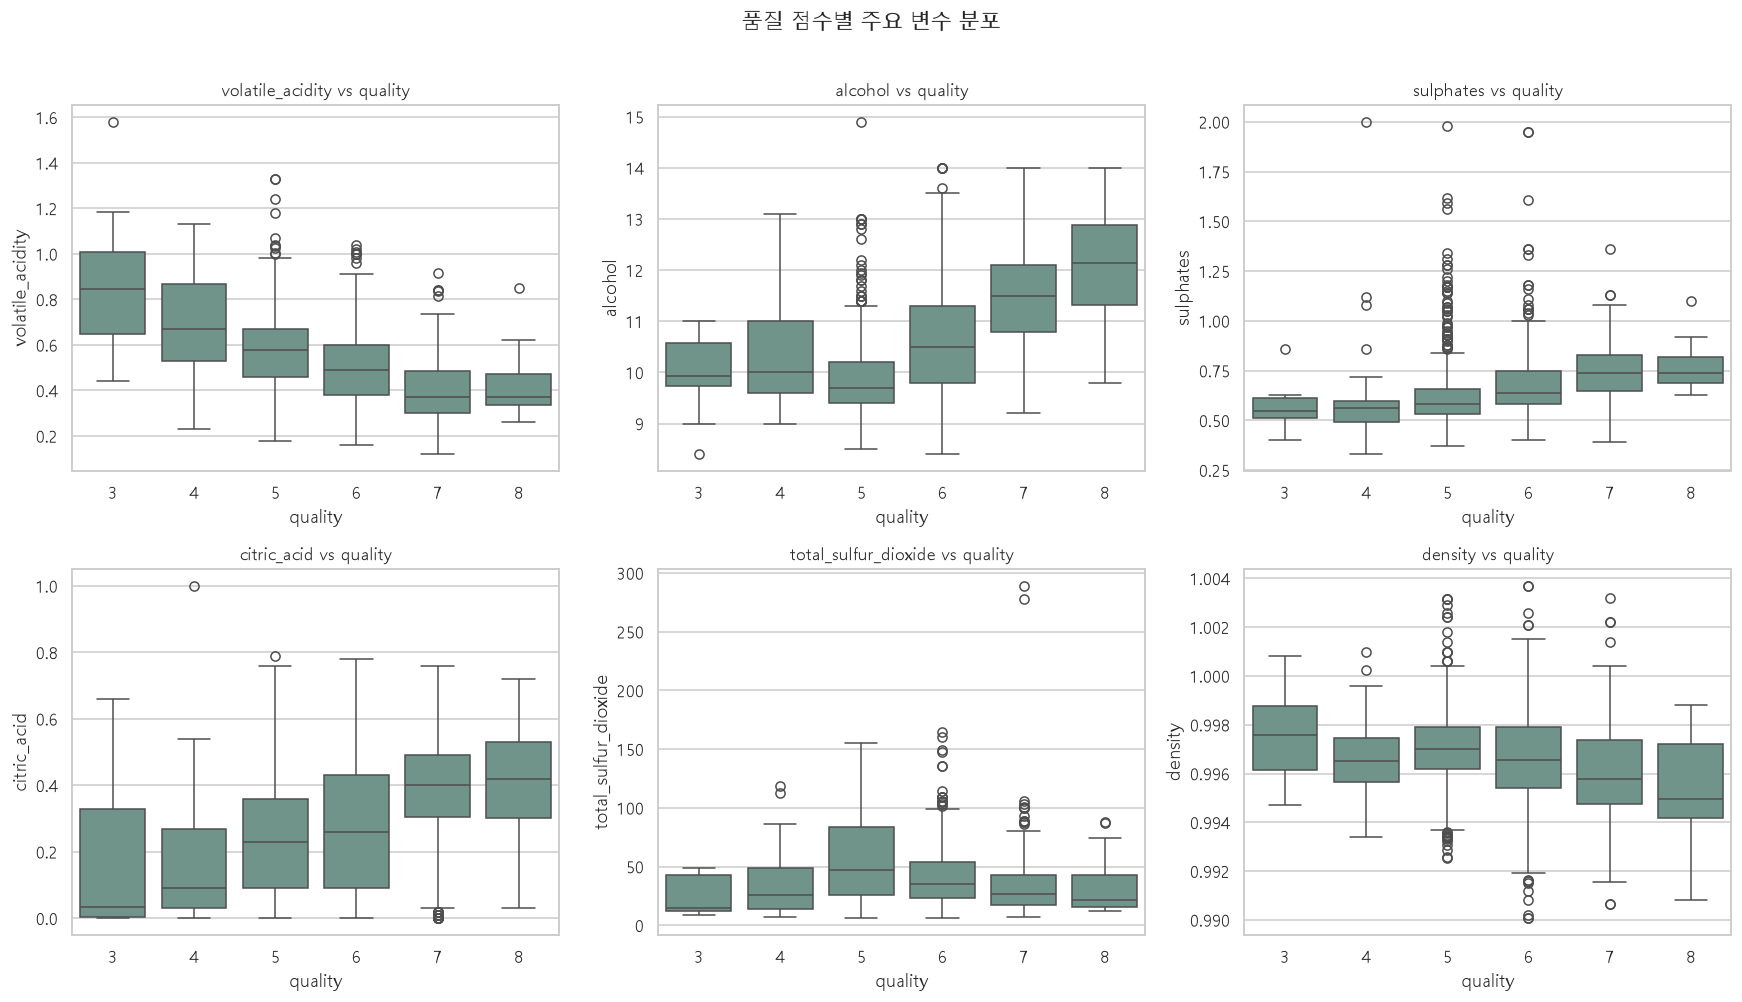

In [10]:
cols = ["volatile_acidity", "alcohol", "sulphates", "citric_acid", "total_sulfur_dioxide", "density"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, f in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="quality", y=f, ax=ax, color="#6a9a8b")
    ax.set_title(f"{f} vs quality", fontsize=11)
fig.suptitle("품질 점수별 주요 변수 분포", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. 품질 예측 모델링

**문제 정의**: 품질 점수를 이진 분류한다. 품질 ≥ 7 을 "우수(1)", 그 미만을 "보통(0)"으로 정의한다.
이는 실무에서 "우수 와인 후보를 선별"하는 용도에 부합한다.

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

X = df.drop(columns=["quality"])
y = (df["quality"] >= 7).astype(int)

print("우수 와인 비율: {:.2%} ({}/{}개)".format(y.mean(), y.sum(), len(y)))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("학습:", X_train.shape, " 테스트:", X_test.shape)

우수 와인 비율: 13.57% (217/1599개)
학습: (1279, 11)  테스트: (320, 11)


In [12]:
results = {}

lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train_s, y_train)
pred_lr, prob_lr = lr.predict(X_test_s), lr.predict_proba(X_test_s)[:, 1]
results["LogisticRegression"] = [accuracy_score(y_test, pred_lr),
                                 f1_score(y_test, pred_lr),
                                 roc_auc_score(y_test, prob_lr)]

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)
pred_rf, prob_rf = rf.predict(X_test), rf.predict_proba(X_test)[:, 1]
results["RandomForest"] = [accuracy_score(y_test, pred_rf),
                           f1_score(y_test, pred_rf),
                           roc_auc_score(y_test, prob_rf)]

metrics_df = pd.DataFrame(results, index=["Accuracy", "F1", "ROC-AUC"]).T
metrics_df.round(4)

,Accuracy,F1,ROC-AUC
LogisticRegression,0.8125,0.5312,0.8824
RandomForest,0.9250,0.7143,0.9429


RandomForest 분류 리포트:

              precision    recall  f1-score   support

          보통       0.95      0.96      0.96       277
          우수       0.73      0.70      0.71        43

    accuracy                           0.93       320
   macro avg       0.84      0.83      0.84       320
weighted avg       0.92      0.93      0.92       320



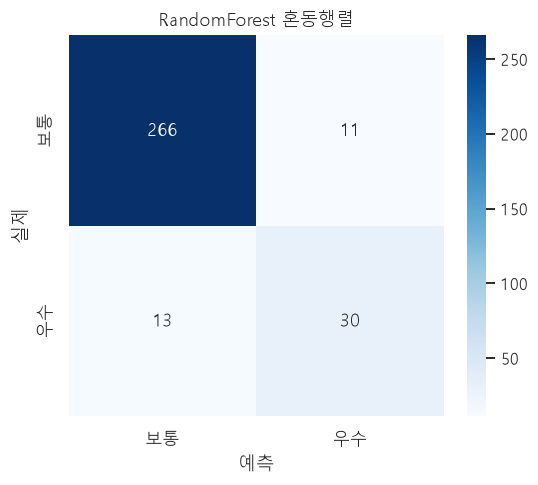

In [13]:
print("RandomForest 분류 리포트:\n")
print(classification_report(y_test, pred_rf, target_names=["보통", "우수"]))

cm = confusion_matrix(y_test, pred_rf)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["보통", "우수"], yticklabels=["보통", "우수"], ax=ax)
ax.set_xlabel("예측")
ax.set_ylabel("실제")
ax.set_title("RandomForest 혼동행렬")
plt.show()

In [14]:
# 5-fold 교차검증 (ROC-AUC)
cv = cross_val_score(
    RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"),
    X, y, cv=5, scoring="roc_auc")
print("교차검증 ROC-AUC: {:.4f} (+/- {:.4f})".format(cv.mean(), cv.std()))

교차검증 ROC-AUC: 0.8660 (+/- 0.0332)


### 5-1. 변수 중요도

RandomForest가 우수 와인 분류에 어떤 변수를 중요하게 사용했는지 확인한다.

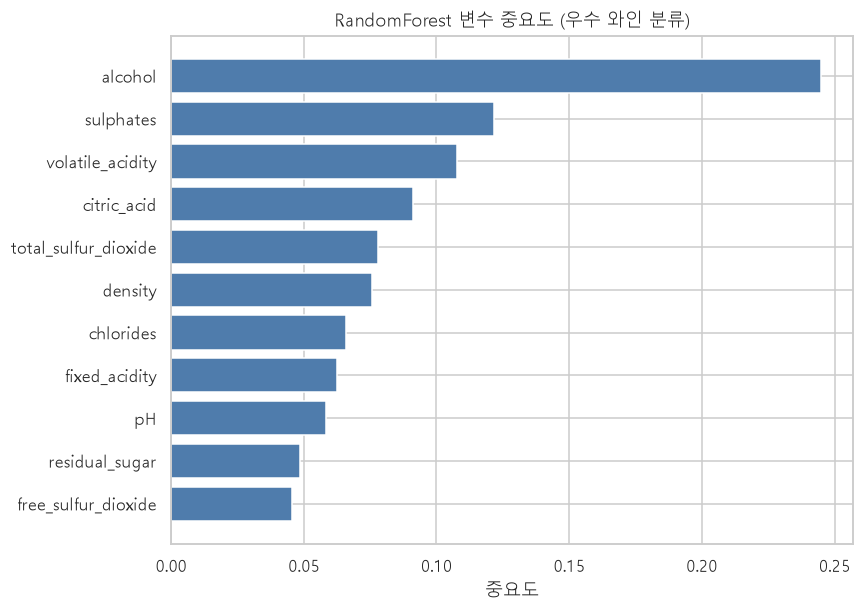

상위 5개 변수:
alcohol                 0.2448
sulphates               0.1218
volatile_acidity        0.1076
citric_acid             0.0912
total_sulfur_dioxide    0.0779
dtype: float64


In [15]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importances.index, importances.values, color="#4f7cac")
ax.set_title("RandomForest 변수 중요도 (우수 와인 분류)")
ax.set_xlabel("중요도")
plt.show()

print("상위 5개 변수:")
print(importances.sort_values(ascending=False).head(5).round(4))

## 6. 결론

| 항목 | 내용 |
|---|---|
| 데이터 | 레드와인 1,599개, 화학적 변수 11개 + 품질 |
| 결측치 | 0개 (중복 240개) |
| 품질 분포 | 5·6점에 집중(약 82%), 7점 이상은 13.6% |
| 주요 변수 | 알코올(+), 황산염(+), 구연산(+) / 휘발성 산도(-) |
| 모델 성능 | RandomForest **Accuracy 0.925 / ROC-AUC 0.943** (교차검증 0.866) |

**해석 및 시사점**
- 알코올 도수가 높고, 휘발성 산도(식초 맛)가 낮으며, 황산염이 적절한 와인이 높은 품질로 평가되는 경향이 있다.
- 품질 점수가 소수 클래스(7·8점)에 치우쳐 있어, class_weight 보정과 ROC-AUC 중심 평가가 적절하다.
- RandomForest가 로지스틱 회귀보다 우수 클래스(F1 0.71)를 더 잘 탐지한다.
- 향후 개선: 하이퍼파라미터 튜닝(GridSearch), 3-class/회귀 모델 비교, 중복 제거 후 재학습.

**한계**
- 중복 데이터, 소수 클래스로 인한 일반화 제약.
- 관측 데이터 기반이라 인과관계로 해석할 수 없다.